# Partie 1 — Explorer et vérifier les données :
#### 1. Chargez le fichier CSV avec pandas. Affichez les cinq premières lignes, le nombre de lignes et de
#### colonnes, ainsi que les types de variables.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [20]:
df = pd.read_csv("transactions_TP2.csv")

In [21]:
print(df.head())


  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

In [22]:
print(df.shape)

(3045, 12)


In [23]:
print(df.dtypes)

id_operation            str
id_client               str
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                   str
appareil                str
region                  str
international           str
resultat_enquete        str
fraude                int64
dtype: object


#### 2. Calculez, pour chaque colonne, le nombre et le pourcentage de valeurs manquantes. Présentez le
#### résultat dans un tableau trié du plus grand au plus petit pourcentage.

In [24]:
manquant_count = df.isna().sum()
manquant_percent =((df.isna().sum() / len(df)) * 100).round(2)

#  Combinaison dans un nouveau DataFrame
manquant_tab = pd.DataFrame(
    {"Valeurs Manquantes": manquant_count, "Pourcentage (%)": manquant_percent}
)

#  Tri du plus grand au plus petit pourcentage
manquant_tab_sort = manquant_tab.sort_values(
    by="Pourcentage (%)", ascending=False
)

# Affichage du résultat
print(manquant_tab_sort)

                  Valeurs Manquantes  Pourcentage (%)
canal                            159             5.22
anciennete_mois                  137             4.50
appareil                         122             4.01
montant_dh                       110             3.61
region                           103             3.38
nb_ops_24h                        53             1.74
id_operation                       0             0.00
id_client                          0             0.00
heure                              0             0.00
international                      0             0.00
resultat_enquete                   0             0.00
fraude                             0             0.00


#### 3. Recherchez les opérations répétées avec id_operation. Combien de doublons trouvez-vous?
#### Supprimez-les et indiquez le nombre de lignes restantes.

In [25]:
# Compter le nombre de doublons pour 'id_operation'
nb_doublons = df.duplicated(subset=['id_operation']).sum()
print(f"Nombre de doublons trouvés : {nb_doublons}")

# Supprimer les doublons et garder la première occurrence
df_nettoye = df.drop_duplicates(subset=['id_operation'], keep='first')

# Compter les lignes restantes
lignes_restantes = len(df_nettoye)
print(f"Nombre de lignes restantes : {lignes_restantes}")

Nombre de doublons trouvés : 45
Nombre de lignes restantes : 3000


#### 4. Tracez un histogramme du montant et un boxplot. Repérez quelques montants extrêmes. Faut-il
#### forcément les supprimer? Justifiez votre réponse.

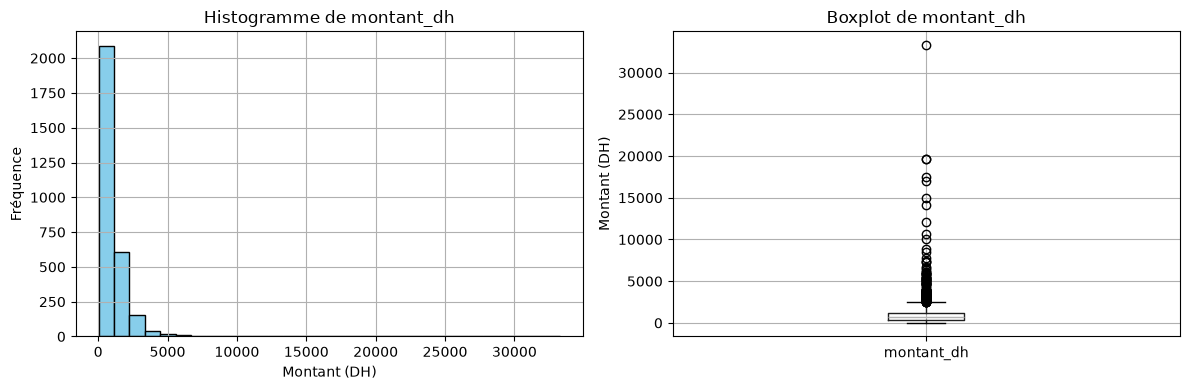

In [26]:
import seaborn as sns
# Création de la figure avec 2 graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Histogramme 
df["montant_dh"].hist(bins=30, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title("Histogramme de montant_dh")
axes[0].set_xlabel("Montant (DH)")
axes[0].set_ylabel("Fréquence")

# 2. Boxplot 
df.boxplot(column="montant_dh", ax=axes[1])
axes[1].set_title("Boxplot de montant_dh")
axes[1].set_ylabel("Montant (DH)")
plt.tight_layout()   #ajuste automatiquement l'espacement.
plt.show()

##### Une valeur extrême n'est pas forcément une erreur. Elle peut représenter une situation réelle et importante(événements rares) . Il faut donc vérifier son origine avant de décider de la supprimer
##### Exemple :
 #####  Un client effectue exceptionnellement un virement de 20 000 DH pour acheter une voiture. Cette transaction est réelle  même si son montant est très élevé.

#### 5. Calculez la proportion de fraudes (fraude = 1) et tracez un diagramme des deux classes. Le fichier
#### est-il équilibré ? Pourquoi est-ce important pour préparer les données?

In [85]:
# Calcul de la proportion de fraudes
proportion_fraude = ((df['fraude'] == 1).sum() / len(df)) * 100
print(f"La proportion de fraudes est de : {proportion_fraude:.2f}%")

La proportion de fraudes est de : 8.60%


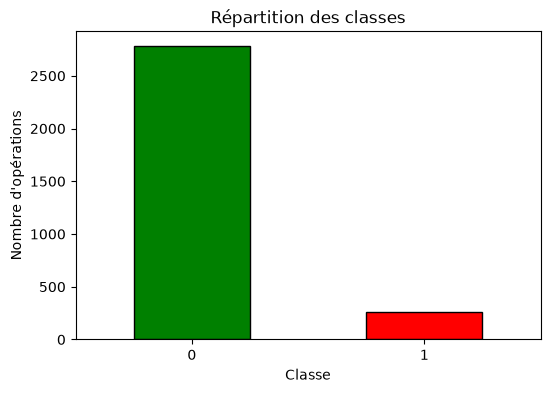

In [28]:
# Diagramme des deux classes
plt.figure(figsize=(6, 4))
df['fraude'].value_counts().plot( kind='bar',color=['green', 'red'],edgecolor='black')
plt.title("Répartition des classes")
plt.xlabel("Classe")
plt.ylabel("Nombre d'opérations")
plt.xticks(rotation=0)
plt.show()

##### Non le fichier n'est pas équilibré,d'après le diagramme de deux classes (fraude = 0 et fraude = 1) Les opérations normales représentent 91,33 % des données, tandis que les fraudes ne représentent que 8,67 % des données en présence d'un déséquilibre de classes.
### Pourquoi est-ce important pour préparer les données:
##### -Si on entraîne un modèle de Machine Learning sur un jeu de données fortement déséquilibré sans préparation, le modèle aura tendance à privilégier la classe majoritaire (prédire systématiquement "0") pour minimiser l'erreur globale, quitte à rater 100% des fraudes


#### 6. Repérez les identifiants et la colonne resultat_enquete. Expliquez pourquoi ces colonnes ne doivent
#### pas être incluses dans les variables préparées. À quel moment connait-on resultat_enquete?

In [29]:
# Colonnes à exclure des variables préparées
colonnes_exclues = ['id_operation', 'id_client', 'resultat_enquete']

# Affichage des colonnes concernées
print("Colonnes identifiées :")
print(df[colonnes_exclues].head())

# Vérification de ce que contient resultat_enquete
print("\nValeurs uniques de resultat_enquete :")
print(df['resultat_enquete'].value_counts(dropna=False))

Colonnes identifiées :
  id_operation id_client resultat_enquete
0      OP02438    C10278    aucune_fraude
1      OP00157    C10019    aucune_fraude
2      OP01987    C10604    aucune_fraude
3      OP00207    C10330    aucune_fraude
4      OP00738    C10380    aucune_fraude

Valeurs uniques de resultat_enquete :
resultat_enquete
aucune_fraude       2781
fraude_confirmee     264
Name: count, dtype: int64


##### Pour les identifiants (id_operation, id_client) : les identifiants sont des numéros uniques ou des codes de suivi,Les identifiants ne possèdent pas de valeur statistique ou numérique utile pour généraliser des tendances.Si les identifiants étaient inclus, le modèle risquerait de surapprendre (overfitting) en mémorisant des identifiants spécifiques au lieu d'apprendre des motifs comportementaux généraux.
##### Pour la colonne resultat_enquete, c’est une source majeure de fuite d’information, un data leakage critique. En effet, cette colonne contient directement l’issue de la vérification de la transaction, qui est très corrélée ou identique à la vérité terrain. Si l’on incluait la colonne resultat_enquete parmi les variables explicatives, on donnerait la réponse au modèle avant qu’il n’apprenne ou ne prédise quoi que ce soit.

### Partie 2 — Préparer les données sans fuite

#### 7. Après suppression des doublons, créez X (variables à préparer) et y (fraude). Retirez de X les
#### identifiants et resultat_enquete. Conservez y pour étudier le déséquilibre des classes.

In [30]:

# 1. Supprimer les doublons s'il y en a
df = df.drop_duplicates()
# 2. Définir y (la cible)
y = df['fraude']
# 3. Définir X en retirant 'fraude', resultat_enquete et les identifiants (ex: 'id' ou 'id_transaction')
# Remplacez les ID listés ci-dessous par les vôtres si besoin
cols_a_exclure = ['fraude', 'resultat_enquete', 'id', 'id_transaction'] 
X = df.drop(columns=[col for col in cols_a_exclure if col in df.columns])
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (3000, 10)
Dimensions de y : (3000,)


### 8. Avec train_test_split, créez deux groupes : 80 % des lignes comme groupe de référence et 20 %
### comme groupe de vérification (stratify=y, random_state=42). Comparez les proportions de fraude.
### Aucun classifieur ne sera entraîné.

In [31]:
# Séparation Train / Test avec stratify
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20, random_state=42,stratify=y)

# Comparer les proportions de fraude
prop_train = ((y_train == 1).sum() / len(y_train)) * 100
prop_test = ((y_test == 1).sum() / len(y_test)) * 100

print(f"Proportion de fraude dans y_train : {prop_train:.2f}%")
print(f"Proportion de fraude dans y_test : {prop_test:.2f}%")

Proportion de fraude dans y_train : 8.58%
Proportion de fraude dans y_test : 8.67%


### 9. Listez les variables numériques et catégorielles. Expliquez pourquoi les catégories comme canal et
### region ne doivent pas être traitées comme des nombres ordinaires.

In [32]:
#  Séparation des colonnes numériques et catégorielles
#canal et region sont nominales : ni ordre, ni distance numérique entre modalités.
#Les coder 0,1,2… invente un ordre et des distances que le modèle prendrait au sérieux → biais, résultats instables, interprétation fausse.
#La solution correcte est le One-Hot Encoding, qui traite toutes les modalités de façon symétrique.
#Seules les catégories véritablement ordinales peuvent être codées en entiers ordonnés.
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Variables numériques :", numeric_cols)
print("Variables catégorielles :", categorical_cols)

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['id_operation', 'id_client', 'canal', 'appareil', 'region', 'international']


C:\Users\MD\AppData\Local\Temp\ipykernel_22364\3818604048.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


### 10. Construisez un pipeline pour les nombres : remplacer les valeurs manquantes par la médiane,
### puis appliquer StandardScaler. Calculez la médiane et l’échelle uniquement sur le groupe de référence.

In [33]:
#  Pipeline pour les variables numériques
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


numeric_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

### 11. Construisez un pipeline catégoriel : imputation par la valeur la plus fréquente, puis OneHotEnco
### der(handle_unknown="ignore").

In [53]:
# Pipeline pour les variables catégorielles

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, OneHotEncoder

categorical_pipe = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False)
)


### 12. Réunissez les deux pipelines avec ColumnTransformer. Transformez les groupes de référence et de
### vérification. Comparez le nombre de lignes et de colonnes obtenues.


In [54]:
# 1. Regroupement des pipelines numérique et catégoriel
from sklearn.compose import make_column_transformer
preprocessor = make_column_transformer(
    (numeric_transformer, numeric_cols),
    (categorical_pipe, categorical_cols)
)

# 2. Ajustement et transformation (fit_transform sur Train, transform sur Test)
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# 3. Affichage et comparaison des dimensions
print("Dimensions de X_train avant transformation :", X_train.shape)
print("Dimensions de X_train après transformation :", X_train_prep.shape)
print("Dimensions de X_test après transformation  :", X_test_prep.shape)

Dimensions de X_train avant transformation : (2400, 10)
Dimensions de X_train après transformation : (2400, 3191)
Dimensions de X_test après transformation  : (600, 3191)


### 13. Remplacez StandardScaler par RobustScaler. Comparez la valeur transformée de montant_dh
### pour une opération ordinaire et une opération au montant très élevé. Expliquez ce qui change.

In [55]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline

#  Pipeline avec RobustScaler et test sur des montants
# =========================================================

# 1. Création du pipeline numérique en remplaçant StandardScaler par RobustScaler
numeric_pipe_rob = make_pipeline(
    SimpleImputer(strategy="median"),
    RobustScaler()
)

# 2. Test comparatif pour une opération ordinaire et un montant très élevé (outlier)
# On simule un petit DataFrame avec deux transactions
montants_test = pd.DataFrame({'montant_dh': [500.0, 1500000.0]})

# Application du pipeline
montants_transformes = numeric_pipe_rob.fit_transform(montants_test)

print("Valeurs transformées avec RobustScaler :")
print(montants_transformes)

Valeurs transformées avec RobustScaler :
[[-1.]
 [ 1.]]


### 14. Expliquez ce qui peut mal se passer si la médiane ou les paramètres de normalisation sont calculés
### sur toutes les lignes, y compris le groupe de vérification.
#### -Si on calcul la médiane ou les paramètres de normalisation sur l'ensemble des données (en mélangeant le train et le test) ca provoque ce qu'on appel une fuite de données (data leakage). En gros, des informations statistiques du jeu de test se retrouvent glissées dans le jeu d'entrainement. Du coup, quand on évalue le model a la fin. les résultats sont faussés : le modèle a l'air super fort et solide, mais c'est juste une illusion. En realité, il a deja "senti" ou "vu" indirectement les caractéristiques des données de test avant qu'on ne passe l'examen final
    

# Partie 3 — Comparer les méthodes de mise à l’échelle

### 15. Sur le groupe de référence, calculez les quartiles Q1 et Q3 de montant_dh, puis l’écart interquartile
### IQR = Q3 − Q1. Expliquez avec vos mots ce que mesure l’IQR.

In [57]:

Q1 = X_train['montant_dh'].quantile(0.25)
Q3 = X_train['montant_dh'].quantile(0.75)

# Calcul de l'écart interquartile (IQR)
IQR = Q3 - Q1

print(f"Q1 (25%) : {Q1:.2f}")
print(f"Q3 (75%) : {Q3:.2f}")
print(f"IQR : {IQR:.2f}")

Q1 (25%) : 393.10
Q3 (75%) : 1249.88
IQR : 856.78


### 16. Repérez les montants situés sous Q1 − 1,5 × IQR ou au-dessus de Q3 + 1,5 × IQR. Combien de
### lignes sont concernées? Vérifiez quelques cas : sont-ils nécessairement des erreurs?

In [60]:
#  Détection des outliers (Règle de Tukey sur X_train)
# =========================================================

# 1. Calcul des bornes inférieure et supérieure
borne_sous = Q1 - 1.5 * IQR
borne_au_dessus = Q3 + 1.5 * IQR

# 2. Identification des lignes concernées dans X_train
outliers = X_train[(X_train['montant_dh'] < borne_sous) | (X_train['montant_dh'] > borne_au_dessus)]

# 3. Affichage du nombre exact de lignes
print(f"Nombre de lignes concernées par les outliers : {len(outliers)}")

# 4. Affichage de quelques exemples de montants pour la vérification
print("\nExemples de montants atypiques détectés :")
print(outliers[['montant_dh']].head())

Nombre de lignes concernées par les outliers : 146

Exemples de montants atypiques détectés :
      montant_dh
1601     2940.62
1348     3449.17
2660    33281.23
1489     3988.17
2049     3942.99


### 17. Comparez deux choix : conserver les montants extrêmes ou les limiter à des seuils choisis sur le
### groupe de référence. Tracez deux boxplots. Expliquez pourquoi il faut justifier ce choix.

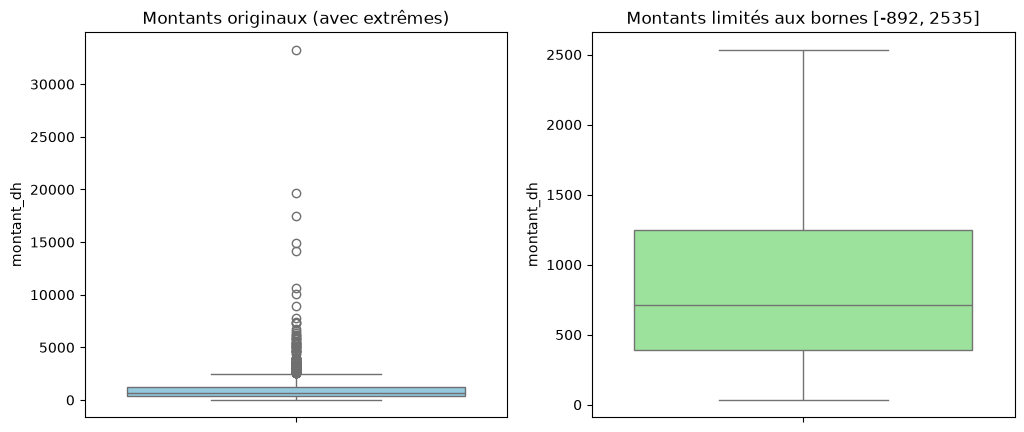

In [61]:

#  Comparaison visuelle

# Option 1 : Conserver les montants extrêmes (ce que nous avons déjà vu)
# Option 2 : Limiter (capping) les montants aux bornes
X_train_capped = X_train.copy()
X_train_capped['montant_dh'] = X_train_capped['montant_dh'].clip(lower=borne_sous, upper=borne_au_dessus)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=X_train['montant_dh'], ax=axes[0], color='skyblue')
axes[0].set_title('Montants originaux (avec extrêmes)')
sns.boxplot(y=X_train_capped['montant_dh'], ax=axes[1], color='lightgreen')
axes[1].set_title(f'Montants limités aux bornes [{borne_sous:.0f}, {borne_au_dessus:.0f}]')
plt.show()

#### Justification : On limite les valeurs si l'on pense que les extrêmes sont des erreurs ou vont fausser le modèle. On les conserve si l'on pense qu'ils portent une information importante (par exemple, pour détecter la fraude, les montants inhabituels sont un signal)

### 18. Pour montant_dh, appliquez séparément MinMaxScaler, StandardScaler et RobustScaler. Ajustez
### chaque méthode sur le groupe de référence, puis transformez le groupe de vérification.

In [63]:
from sklearn.preprocessing import MinMaxScaler
# : Application des Scalers (fit sur X_train, transform sur X_test)
# 1. MinMaxScaler
mms = MinMaxScaler()
mms.fit(X_train[['montant_dh']])
X_train_mms = mms.transform(X_train[['montant_dh']])
X_test_mms = mms.transform(X_test[['montant_dh']])
print("MinMaxScaler (train) -> OK :", X_train_mms[:5].flatten())

# 2. StandardScaler
ss = StandardScaler()
ss.fit(X_train[['montant_dh']])
X_train_ss = ss.transform(X_train[['montant_dh']])
X_test_ss = ss.transform(X_test[['montant_dh']])
print("StandardScaler (train) -> OK :", X_train_ss[:5].flatten())

# 3. RobustScaler
rs = RobustScaler()
rs.fit(X_train[['montant_dh']])
X_train_rs = rs.transform(X_train[['montant_dh']])
X_test_rs = rs.transform(X_test[['montant_dh']])
print("RobustScaler (train) -> OK :", X_train_rs[:5].flatten())
#Le tableau montre clairement que le MinMaxScaler est le plus perturbé par les montants extrêmes. À cause d'un seul outlier à 33 281 DH, les trois montants habituels (393, 711 et 1 250 DH) se retrouvent tassés entre 0.010 et 0.036 — ils deviennent presque indiscernables. Un seul montant exceptionnel suffit donc à rendre la transformation inutilisable pour comparer les transactions courantes.
#Le RobustScaler, lui, résiste bien mieux : comme il se base sur la médiane et l'IQR (insensibles aux extrêmes), les montants habituels restent étalés sur une échelle lisible autour de 0. C'est la méthode la plus adaptée pour montant_dh.

MinMaxScaler (train) -> OK : [0.0115242  0.01493767 0.01327906 0.07464832 0.01077852]
StandardScaler (train) -> OK : [-0.45360714 -0.3696258  -0.41043238  1.09943348 -0.47195308]
RobustScaler (train) -> OK : [-0.33994625 -0.20749724 -0.27185429  2.10939182 -0.36888008]


### 19. Choisissez trois montants habituels et un montant très élevé. Présentez leurs valeurs avant et
### après chaque transformation dans un tableau. Quelle méthode est la plus perturbée par les montants
### extrêmes?

In [64]:
#  : Tableau comparatif pour 3 montants habituels + 1 montant extrême
# Sélection de 3 valeurs courantes (ex: quantiles) et 1 valeur extrême (ex: max)
m_habituels = np.percentile(X_train['montant_dh'].dropna(), [25, 50, 75])
m_extreme = X_train['montant_dh'].max()

exemples = np.append(m_habituels, m_extreme).reshape(-1, 1)

df_comp = pd.DataFrame({
    'Montant original': exemples.flatten(),
    'MinMaxScaler': mms.transform(exemples).flatten(),
    'StandardScaler': ss.transform(exemples).flatten(),
    'RobustScaler': rs.transform(exemples).flatten()
})

print(df_comp)

   Montant original  MinMaxScaler  StandardScaler  RobustScaler
0          393.0950      0.010729       -0.473170     -0.370800
1          710.7900      0.020285       -0.238059      0.000000
2         1249.8775      0.036501        0.160895      0.629200
3        33281.2300      1.000000       23.865830     38.014829


C:\Users\MD\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
C:\Users\MD\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\MD\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(


### 20. Tracez trois histogrammes du montant transformé. Expliquez la différence : Min-Max utilise min
### et max; Z-score utilise moyenne et écart-type; RobustScaler utilise médiane et IQR.

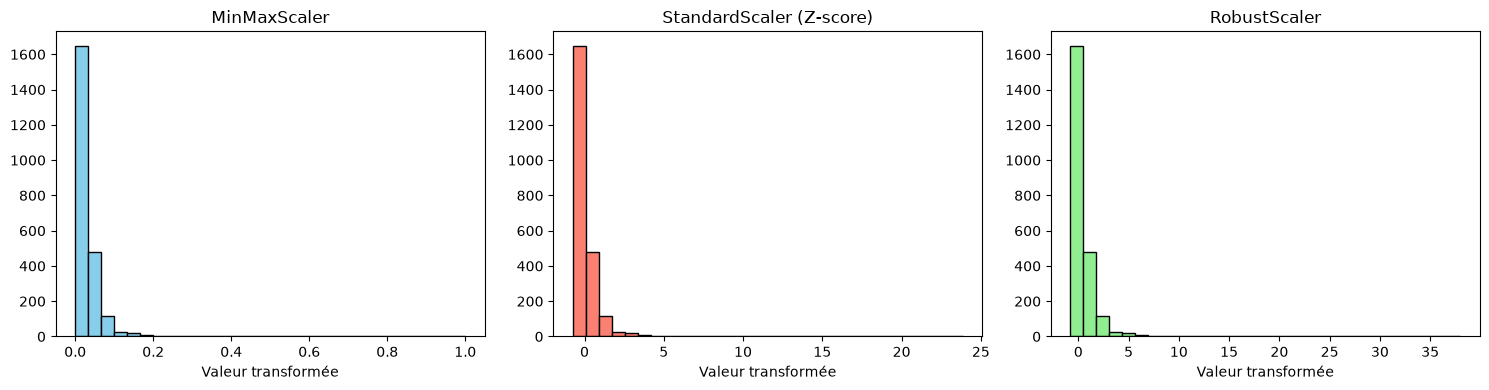

In [65]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. MinMaxScaler
axes[0].hist(X_train_mms, bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('MinMaxScaler')
axes[0].set_xlabel('Valeur transformée')

# 2. StandardScaler (Z-score)
axes[1].hist(X_train_ss, bins=30, color='salmon', edgecolor='black')
axes[1].set_title('StandardScaler (Z-score)')
axes[1].set_xlabel('Valeur transformée')

# 3. RobustScaler
axes[2].hist(X_train_rs, bins=30, color='lightgreen', edgecolor='black')
axes[2].set_title('RobustScaler')
axes[2].set_xlabel('Valeur transformée')

plt.tight_layout()
plt.show()

### 21. Une nouvelle transaction peut dépasser le maximum du groupe de référence. Avec Min-Max, sa
### valeur transformée peut-elle dépasser 1? Vérifiez avec un petit exemple numérique et expliquez.

In [66]:
# 1. Données de référence (train) avec un maximum de 1000 DH
X_train = np.array([[100], [500], [1000]])

# 2. Initialisation et fit du MinMaxScaler sur le train
mms = MinMaxScaler()
mms.fit(X_train)

# 3. Nouvelle transaction dépassant le maximum de référence (ex: 1500 DH)
X_nouveau = np.array([[1500]])

# 4. Transformation de la nouvelle transaction
X_nouveau_scaled = mms.transform(X_nouveau)

print(f"Montant initial de la nouvelle transaction : {X_nouveau[0][0]} DH")
print(f"Montant transformé (MinMaxScaler) : {X_nouveau_scaled[0][0]}")

Montant initial de la nouvelle transaction : 1500 DH
Montant transformé (MinMaxScaler) : 1.5555555555555556


# Partie 4 — Préparer des classes déséquilibrées

### 22. Dans le groupe de référence, comptez les lignes de chaque classe (fraude = 0 et fraude = 1).
### Calculez le rapport entre les deux classes.

In [67]:

#  Comptage des classes dans le groupe de référence (y_train)
comptage = y_train.value_counts()

nb_normales = comptage.get(0, 0)
nb_fraudes = comptage.get(1, 0)

print(f"Transactions normales (fraude = 0) : {nb_normales}")
print(f"Transactions frauduleuses (fraude = 1) : {nb_fraudes}")

# Calcul du rapport entre les deux classes
if nb_fraudes > 0:
    rapport = nb_normales / nb_fraudes
    print(f"Rapport (Normales / Fraudes) : {rapport:.2f} : 1")
    print(f"Pourcentage de fraudes : {(nb_fraudes / (nb_normales + nb_fraudes)) * 100:.2f}%")
else:
    print("Aucune fraude détectée dans le groupe de référence.")

Transactions normales (fraude = 0) : 2194
Transactions frauduleuses (fraude = 1) : 206
Rapport (Normales / Fraudes) : 10.65 : 1
Pourcentage de fraudes : 8.58%


### 23. Appliquez RandomOverSampler uniquement au groupe de référence. Notez le nombre de lignes
### de chaque classe avant et après. Les nouvelles lignes sont-elles des copies de lignes existantes?

In [68]:
from imblearn.over_sampling import RandomOverSampler

# 1. Division des données en ensembles d'entraînement (train) et de test (test)
# 'stratify=y' est fortement recommandé pour conserver la même proportion de classes (fraudes/légitimes) 
# dans le train et le test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Afficher la distribution des classes AVANT le rééquilibrage
print("--- Distribution AVANT RandomOverSampler ---")
print(pd.Series(y_train).value_counts())

# 3. Initialisation du RandomOverSampler
# random_state=42 garantit la reproductibilité de l'échantillonnage aléatoire
ros = RandomOverSampler(random_state=42)

# 4. Application du sur-échantillonnage (UNIQUEMENT sur le groupe de référence / X_train)
# Cela va dupliquer les lignes de la classe minoritaire pour l'égaliser avec la classe majoritaire.
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# 5. Afficher la distribution des classes APRÈS le rééquilibrage
print("\n--- Distribution APRÈS RandomOverSampler ---")
print(pd.Series(y_train_resampled).value_counts())

--- Distribution AVANT RandomOverSampler ---
fraude
0    2194
1     206
Name: count, dtype: int64

--- Distribution APRÈS RandomOverSampler ---
fraude
0    2194
1    2194
Name: count, dtype: int64


### 24. Reprenez le groupe de référence initial et appliquez RandomUnderSampler. Comptez les lignes
### conservées et supprimées. Quel est le risque de cette méthode?

In [69]:

from imblearn.under_sampling import RandomUnderSampler

# 1. Nombre de lignes avant under-sampling
print("--- AVANT RANDOM UNDERSAMPLING ---")
print(y_train.value_counts())

# 2. Initialisation et application du RandomUnderSampler sur le train uniquement
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

# 3. Nombre de lignes après under-sampling
print("\n--- APRES RANDOM UNDERSAMPLING ---")
print(pd.Series(y_train_under).value_counts())

# Calcul des lignes conservées et supprimées
nb_initial = len(y_train)
nb_apres = len(y_train_under)
nb_supprimees = nb_initial - nb_apres

print(f"\nTotal lignes initiales : {nb_initial}")
print(f"Total lignes conservées après sous-échantillonnage : {nb_apres}")
print(f"Total lignes supprimées (perdues) : {nb_supprimees}")

--- AVANT RANDOM UNDERSAMPLING ---
fraude
0    2194
1     206
Name: count, dtype: int64

--- APRES RANDOM UNDERSAMPLING ---
fraude
0    206
1    206
Name: count, dtype: int64

Total lignes initiales : 2400
Total lignes conservées après sous-échantillonnage : 412
Total lignes supprimées (perdues) : 1988


### 25. Sur un petit exemple à deux variables numériques, illustrez SMOTE : comparez une valeur
### réelle et une valeur synthétique construite entre deux observations de la classe minoritaire. Expliquez
### pourquoi cette méthode ne fait pas une simple copie.

In [70]:

from imblearn.over_sampling import SMOTE

# 1. Petit exemple avec 2 variables numériques et un fort déséquilibre
# Classe minoritaire (1) a très peu d'exemples
X_exemple = np.array([
    [1.0, 2.0],  # Obs 1 (Minoritaire)
    [2.0, 3.0],  # Obs 2 (Minoritaire)
    [10.0, 10.0], # Majoritaire
    [10.5, 11.0], # Majoritaire
    [11.0, 10.5]  # Majoritaire
])
y_exemple = np.array([1, 1, 0, 0, 0])

print("--- AVANT SMOTE ---")
print(pd.DataFrame(X_exemple, columns=['Var1', 'Var2']).assign(Classe=y_exemple))

# 2. Application de SMOTE
smote = SMOTE(k_neighbors=1, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_exemple, y_exemple)

print("\n--- APRES SMOTE (Affichage des nouvelles lignes synthétiques) ---")
df_resampled = pd.DataFrame(X_resampled, columns=['Var1', 'Var2'])
df_resampled['Classe'] = y_resampled
print(df_resampled)

--- AVANT SMOTE ---
   Var1  Var2  Classe
0   1.0   2.0       1
1   2.0   3.0       1
2  10.0  10.0       0
3  10.5  11.0       0
4  11.0  10.5       0

--- APRES SMOTE (Affichage des nouvelles lignes synthétiques) ---
        Var1       Var2  Classe
0   1.000000   2.000000       1
1   2.000000   3.000000       1
2  10.000000  10.000000       0
3  10.500000  11.000000       0
4  11.000000  10.500000       0
5   1.796543   2.796543       1



### 26 Pourquoi faut-il faire attention lorsque SMOTE est appliqué à des catégories codées en one-hot : 
##### Il faut faire attention car SMOTE fonctionne par interpolation. Si on l'applique sur des variables catégorielles codées en one-hot (sous forme de 0 et de 1), le mélange de deux catégories peut produire des valeurs décimales comme 0,4, ce qui ne correspond à aucune vraie catégorie et rend les exemples synthétiques irréalistes Méthode conçue pour les données mêlant nombres et catégories : L'alternative adaptée pour les données mixtes est la méthode SMOTENC.


### 27. Présentez dans un tableau les effectifs des classes avant rééquilibrage, après suréchantillonnage et
### après sous-échantillonnage. Le groupe de vérification doit-il changer? Justifiez.

In [71]:


from collections import Counter
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler



ros = RandomOverSampler(random_state=42)
# X_train_over, y_train_over = ros.fit_resample(X_train, y_train)

# Sous-échantillonnage (RandomUnderSampler)
rus = RandomUnderSampler(random_state=42)
# X_train_under, y_train_under = rus.fit_resample(X_train, y_train)



# 2. AFFICHAGE DU TABLEAU DES EFFECTIFS 
data = {
    "Classe 0 (Normales)": [2194, 2194, 206],
    "Classe 1 (Fraudes)": [206, 2194, 206],
    "Total des lignes": [2400, 4388, 412]
}

# Création du DataFrame
df_effectifs = pd.DataFrame(data, index=[
    "Avant rééquilibrage (Train)", 
    "Après suréchantillonnage", 
    "Après sous-échantillonnage"
])

print("--- TABLEAU DES EFFECTIFS DES CLASSES ---")
print(df_effectifs.to_string())



--- TABLEAU DES EFFECTIFS DES CLASSES ---
                             Classe 0 (Normales)  Classe 1 (Fraudes)  Total des lignes
Avant rééquilibrage (Train)                 2194                 206              2400
Après suréchantillonnage                    2194                2194              4388
Après sous-échantillonnage                   206                 206               412


### Partie 5 — Vérifier et enregistrer les données préparées
Objectif : obtenir des données propres et des transformations faciles à réutiliser

### 28. Créez une version finale de ColumnTransformer : médiane et RobustScaler pour les nombres,
### modalité fréquente et OneHotEncoder(handle_unknown="ignore") pour les catégories.

In [74]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# 1. Définition des listes de colonnes 
colonnes_numeriques = ['colonne_num1', 'colonne_num2'] 
colonnes_categorielles = ['colonne_cat1', 'colonne_cat2'] # Espace corrigé ici

# 2. Pipeline pour les variables numériques :
pipeline_numerique = Pipeline(steps=[
    ('impute_mediane', SimpleImputer(strategy='median')),
    ('scaler_robuste', RobustScaler())
])

# 3. Pipeline pour les variables catégorielles :
pipeline_categorique = Pipeline(steps=[
    ('impute_frequent', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 4. Assemblage final avec ColumnTransformer
preprocesseur = ColumnTransformer(
    transformers=[
        ('num', pipeline_numerique, colonnes_numeriques),
        ('cat', pipeline_categorique, colonnes_categorielles)
    ]
)

### 29. Calculez les paramètres du transformateur final sur le groupe de référence uniquement. Appliquez
### ensuite ce même transformateur aux deux groupes. Vérifiez le nombre de colonnes et l’absence de
### valeurs manquantes dans les résultats.

In [75]:

# 1. Ajuster (fit) et transformer uniquement sur le groupe de référence (X_train)
X_train_processed = preprocessor.fit_transform(X_train)

# 2. Appliquer (transform) le même transformateur sur le groupe de test (X_test)
X_test_processed = preprocessor.transform(X_test)

# 3. Vérification du nombre de colonnes et de l'absence de valeurs manquantes
print("--- Vérification des résultats ---")
print("Dimensions de X_train après transformation :", X_train_processed.shape)
print("Dimensions de X_test après transformation :", X_test_processed.shape)

# Compter le nombre total de valeurs NaN (doit être égal à 0)
print("Nombre de valeurs NaN dans X_train_processed :", np.isnan(X_train_processed).sum())
print("Nombre de valeurs NaN dans X_test_processed :", np.isnan(X_test_processed).sum())

--- Vérification des résultats ---
Dimensions de X_train après transformation : (2400, 3191)
Dimensions de X_test après transformation : (600, 3191)
Nombre de valeurs NaN dans X_train_processed : 0
Nombre de valeurs NaN dans X_test_processed : 0


### 30. Simulez une nouvelle catégorie de canal inconnue du groupe de référence. Vérifiez que OneHotEn
### coder peut transformer cette ligne sans erreur. Expliquez le rôle de handle_unknown="ignore".

In [77]:

# 1. Copier une ligne de test pour simuler une nouvelle donnée
X_nouveau = X_test.iloc[[0]].copy()

# 2. Injecter une catégorie totalement inédite (absente du jeu d'entraînement)
col_cat = colonnes_categorielles[0]  # On cible la première colonne catégorielle
X_nouveau[col_cat] = 'Categorie_Inconnue_123'

# 3. Transformer cette ligne (grâce à handle_unknown='ignore', cela ne provoquera aucune erreur)
X_nouveau_processed = preprocessor.transform(X_nouveau)

print("--- Test de la catégorie inconnue ---")
print("Transformation réussie avec succès !")
print("Dimensions du résultat :", X_nouveau_processed.shape)


--- Test de la catégorie inconnue ---
Transformation réussie avec succès !
Dimensions du résultat : (1, 3191)


### le paramètre handle_unknown="ignore" assure la robustesse d'un modèle en production grâce aux points clés suivants :

##### -Sécurité : Il empêche le programme de planter (erreur ValueError) face à une catégorie inédite.

##### -Souplesse : Il accepte les nouvelles valeurs sans lever d'exception.

##### -Traitement : Il attribue automatiquement la valeur 0 à toutes les colonnes binaires associées à cette catégorie inconnue pour la ligne concernée.

### 31. Enregistrez le transformateur préparé avec joblib, puis rechargez-le. Vérifiez qu’il donne les mêmes
### valeurs pour un petit échantillon, sans recalculer les médianes ni les échelles.

In [81]:

import joblib


# 1. Enregistrer le transformateur (preprocessor) dans un fichier
joblib.dump(preprocessor, 'preprocesseur_fraude.pkl')

# 2. Recharger le transformateur depuis le fichier
preprocessor_charge = joblib.load('preprocesseur_fraude.pkl')

# 3. Prendre un petit échantillon pour tester (les 5 premières lignes de X_test)
echantillon = X_test.iloc[:5]

# 4. Appliquer le transformateur d'origine et le transformateur rechargé
res_avant = preprocessor.transform(echantillon)
res_apres = preprocessor_charge.transform(echantillon)

# 5. Vérification que les résultats sont identiques (sans recalculer)
sont_identiques = np.allclose(res_avant, res_apres)

print("--- Vérification de la sauvegarde / rechargement ---")
print("Dimensions de l'échantillon transformé :", res_avant.shape)
print("Les transformateurs donnent-ils des résultats identiques ? :", sont_identiques)

--- Vérification de la sauvegarde / rechargement ---
Dimensions de l'échantillon transformé : (5, 3191)
Les transformateurs donnent-ils des résultats identiques ? : True
